# Pipeline: De-novo integration vs. mapping with scArches

In [1]:
# import os
# os.chdir('../')
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=UserWarning)

We use the scArches package here, as it includes scANVI as a dependency, and we will need scArches later anyway when mapping new data to the atlas.

In [2]:
import scanpy as sc
import anndata
import torch
import scarches as sca
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


In [3]:
# sc.settings.set_figure_params(dpi=200, frameon=False)
# sc.set_figure_params(dpi=200)
# sc.set_figure_params(figsize=(4, 4))
torch.set_printoptions(precision=3, sci_mode=False, edgeitems=7)

In [4]:
sca.__file__

'/home/icb/jan.domke/miniconda3/envs/scArches/lib/python3.7/site-packages/scarches/__init__.py'

In [5]:
#sc.logging.print_versions()

## 0. Import all relevant datasets

First run LCA_scran normalization with query_data and then import normalized data.

In [6]:
query_data = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/Meyer_2021_norm.h5ad")

In [7]:
source_adata = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/LCA_v4.h5ad")

In [8]:
source_adata.X = source_adata.layers["counts"]

In [9]:
del source_adata.obsm
del source_adata.obsp

In [10]:
atlas_data = sc.read("/storage/groups/ml01/workspace/jan.domke/Data/atlas_data.h5ad")

## 1. Perform de-novo integration

### 1.1 Preparation

In [11]:
source_adata.var = source_adata.var.set_index("gene_ids")

In [12]:
query_data.var["gene_ids"] = query_data.var.index

In [13]:
combined_data = source_adata.concatenate(query_data, join="outer")

In [14]:
combined_data.X = np.nan_to_num(combined_data.X, copy=False)

In [15]:
combined_data.var_keys()

['gene_symbols-0',
 'n_cells-0',
 'highly_variable-0',
 'means-0',
 'dispersions-0',
 'dispersions_norm-0',
 'highly_variable_nbatches-0',
 'highly_variable_intersection-0',
 'gene_symbols-1',
 'gene_ids-1']

In [16]:
combined_data.var["highly_variable-0"].fillna(False, inplace=True)

Create two datasets: 
- combined_data: recalculate hvgs and take top 2000
- combined_data_ref_hvg: take 2000 hvg calculated on reference atlas

In [17]:
combined_data_ref_hvg = combined_data[:,combined_data.var["highly_variable-0"]].copy()

Recalculate highly variable genes

In [18]:
# function to calculate variances on *sparse* matrix
def vars(a, axis=None):
    """ Variance of sparse matrix a
    var = mean(a**2) - mean(a)**2
    """
    a_squared = a.copy()
    a_squared.data **= 2
    return a_squared.mean(axis) - np.square(a.mean(axis))

calculate mean, variance, dispersion per gene:

In [19]:
means = np.mean(combined_data.X, axis=0)

In [20]:
variances = vars(combined_data.X, axis=0)

In [21]:
dispersions = variances / means

/home/icb/jan.domke/miniconda3/envs/scArches/lib/python3.7/site-packages/ipykernel_launcher.py:1: RuntimeWarning: invalid value encountered in true_divide
  """Entry point for launching an IPython kernel.


set min_mean cutoff (base this on the plot). We do not want to include the leftmost noisy genes that have high dispersions due to low means.

In [22]:
min_mean = 0.06

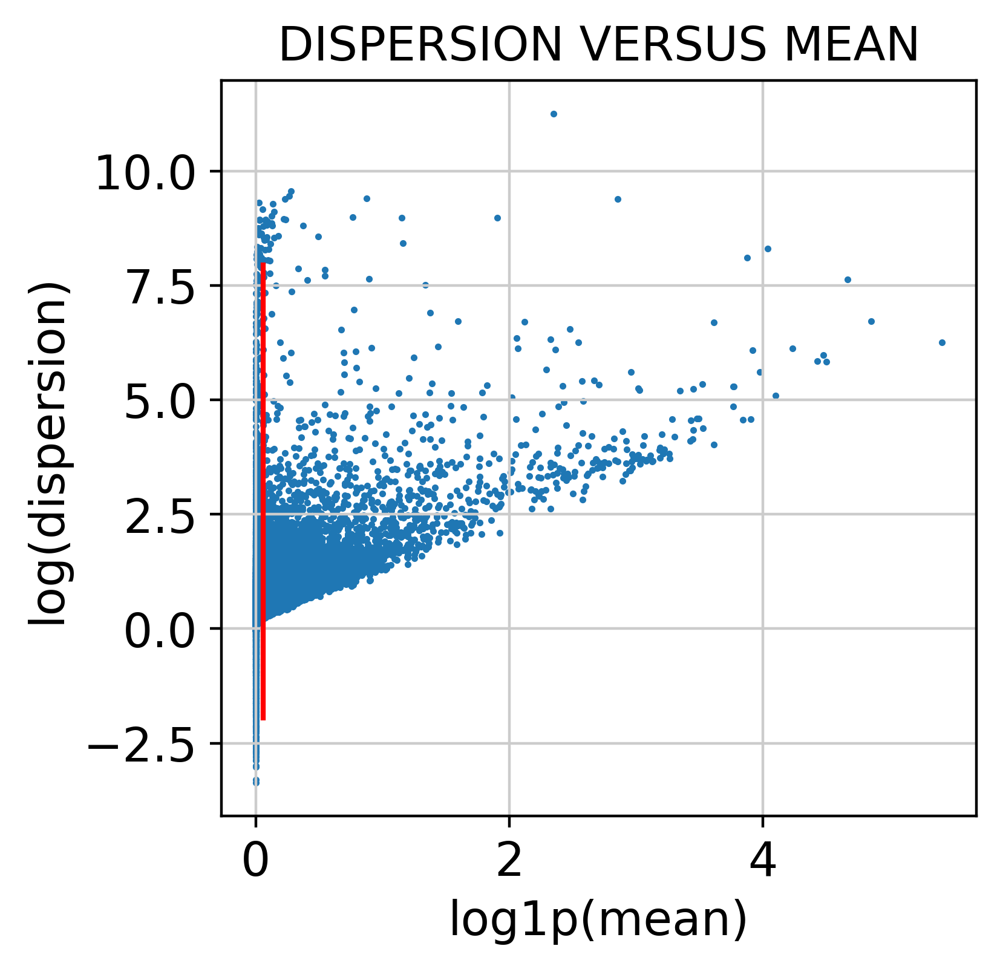

In [23]:
# plot mean versus dispersion plot:
# now plot
plt.scatter(
    np.log1p(means).tolist()[0], np.log(dispersions).tolist()[0], s=1,
    
)
plt.vlines(x=np.log1p(min_mean),ymin=-2,ymax=8,color='red')
plt.xlabel("log1p(mean)")
plt.ylabel("log(dispersion)")
plt.title("DISPERSION VERSUS MEAN")
plt.show()

log-transform data:

In [24]:
sc.pp.log1p(combined_data)

now calculate highly variable genes:

In [25]:
sc.pp.highly_variable_genes(combined_data, batch_key="dataset", min_mean=min_mean, flavor="cell_ranger", n_top_genes=2000)

... storing 'sample' as categorical
... storing 'original_celltype_ann' as categorical
... storing 'study_long' as categorical
... storing 'study' as categorical
... storing 'last_author_PI' as categorical
... storing 'subject_ID' as categorical
... storing 'subject_ID_as_published' as categorical
... storing 'age_range' as categorical
... storing 'ethnicity' as categorical
... storing 'mixed_ethnicity' as categorical
... storing 'smoking_status' as categorical
... storing 'smoking_history' as categorical
... storing 'known_lung_disease' as categorical
... storing 'condition' as categorical
... storing 'subject_type' as categorical
... storing 'cause_of_death' as categorical
... storing 'sample_type' as categorical
... storing 'anatomical_region_coarse' as categorical
... storing 'anatomical_region_detailed' as categorical
... storing 'tissue_dissociation_protocol' as categorical
... storing 'single_cell_platform' as categorical
... storing 'enrichment' as categorical
... storing 'sequ

In [26]:
combined_data.raw = combined_data

check selection of genes:

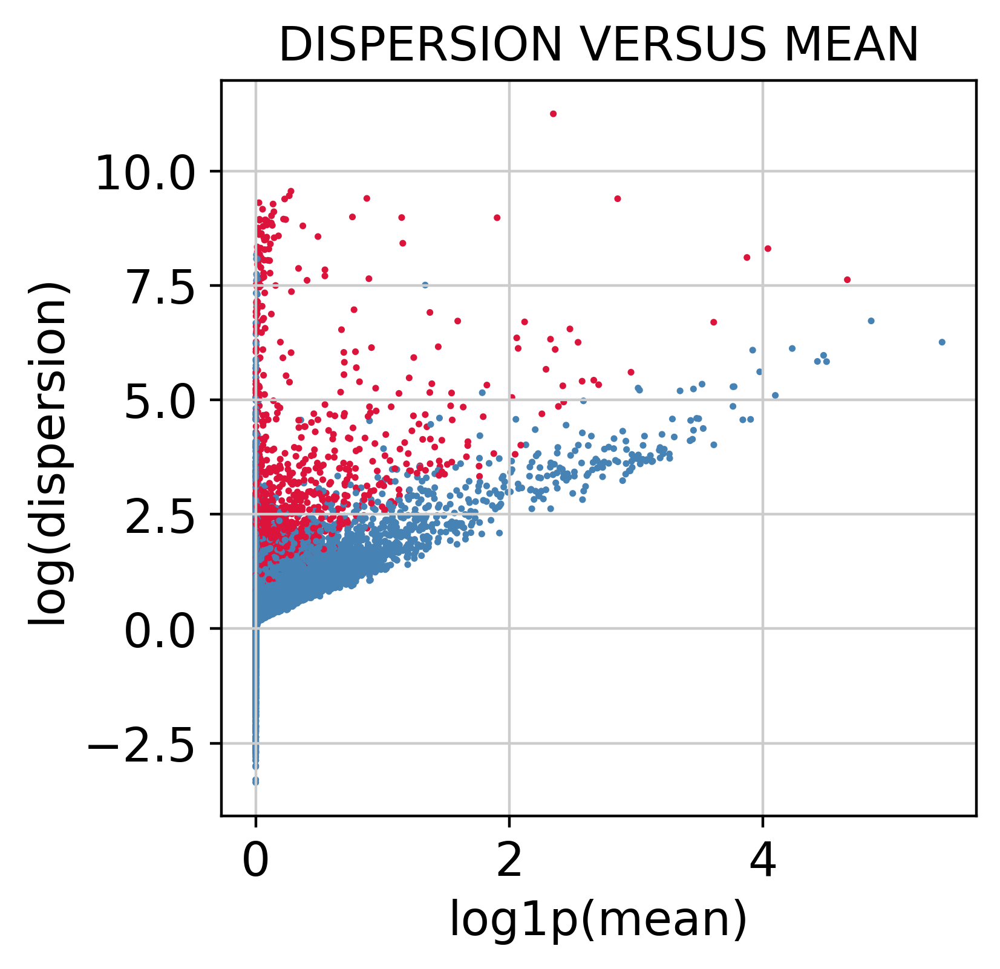

In [27]:
boolean_to_color = {
    True: "crimson",
    False: "steelblue",
}  # make a dictionary that translates the boolean to colors
hvg_colors = combined_data.var.highly_variable.map(boolean_to_color)  # 'convert' the boolean
# now plot
plt.scatter(
    np.log1p(means).tolist()[0], np.log(dispersions).tolist()[0], s=1, c=hvg_colors
)
plt.xlabel("log1p(mean)")
plt.ylabel("log(dispersion)")
plt.title("DISPERSION VERSUS MEAN")
plt.show()

Subset data to the calculated top 2000 highly variable genes

In [28]:
combined_data = combined_data[:,combined_data.var.highly_variable].copy()

In [29]:
np.unique(source_adata.obs.scanvi_label)

array(['AT1', 'AT2', 'Arterial EC', 'B cell lineage', 'Basal',
       'Bronchial Vessel 1', 'Bronchial Vessel 2', 'Capillary',
       'Ciliated', 'Dendritic cells', 'Fibroblast lineage',
       'KRT5- KRT17+ epithelial', 'Lymphatic EC', 'Macrophages',
       'Mast cells', 'Megakaryocytes', 'Mesothelium', 'Monocytes',
       'Neutrophilic', 'Non-T/B cells', 'Proliferating cells', 'Rare',
       'Secretory', 'Smooth muscle', 'Squamous', 'Submucosal Secretory',
       'T cell lineage', 'Venous', 'unlabeled'], dtype=object)

### 1.2 scVI and scANVI model with newly calculated HVGs

In [30]:
condition_key = 'dataset'
cell_type_key = 'scanvi_label'
unlabeled_category = "unlabeled"

scvi_epochs = 500
scanvi_epochs = 200

In [31]:
#sca.dataset.setup_anndata(combined_data, layer="counts", batch_key=condition_key, labels_key=cell_type_key)

Default parameters, except n_latent=30 (higher than default) since we're processing large data with diverse cell types (was also used in benchmarking), and gene_likelihood='nb' instead of zinb since all data are UMI based (hence negative binomially distributed).

In [32]:
#scvi_model = sca.models.SCVI(
#    combined_data,
#    n_layers=2,
#    n_latent=30, 
#    encode_covariates=True,
#    deeply_inject_covariates=False,
#    use_layer_norm="both",
#    use_batch_norm="none",
#    gene_likelihood="nb"
#)

In [33]:
#scvi_model.train(max_epochs=scvi_epochs, early_stopping=True)

In [34]:
#scvi_model.save("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/scVI")

In [35]:
scvi_model = sca.models.SCVI.load("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/scVI", combined_data)

INFO     Using data from adata.layers["counts"]                                              
INFO     Computing library size prior per batch                                              
INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     
INFO     Successfully registered anndata object containing 713512 cells, 2000 vars, 16       
         batches, 37 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  


In [36]:
combined_data.obsm["X_scVI"] = scvi_model.get_latent_representation()

In [37]:
sc.pp.neighbors(combined_data, use_rep="X_scVI")
sc.tl.leiden(combined_data)
sc.tl.umap(combined_data)

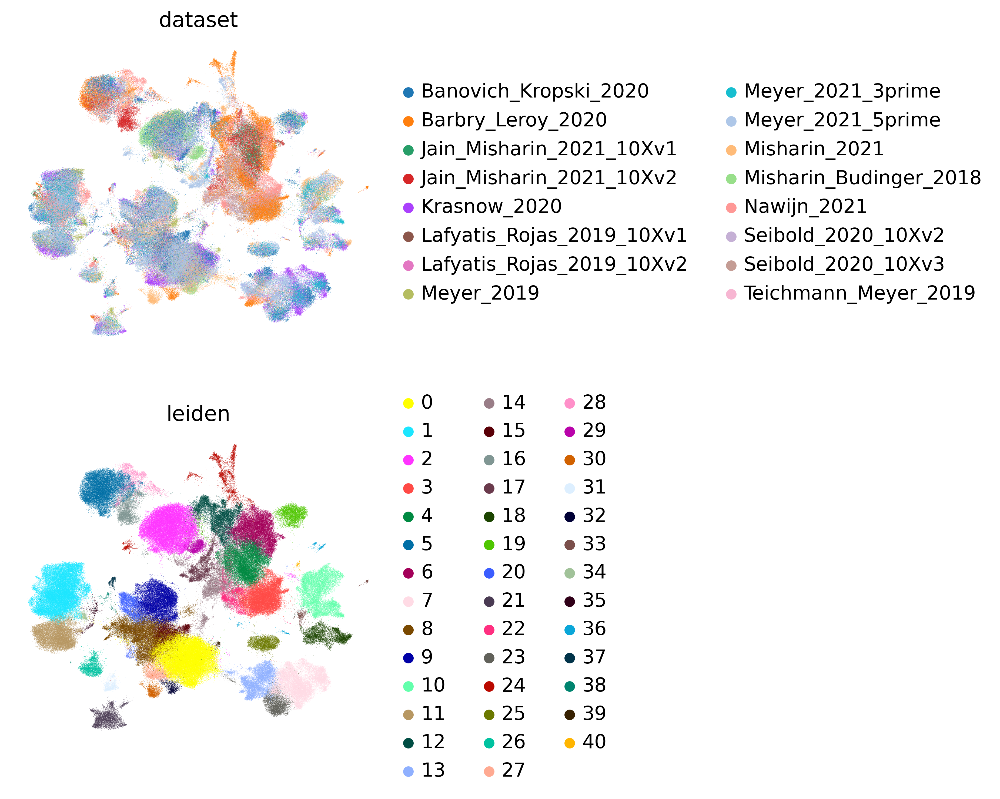

In [38]:
sc.pl.umap(
    combined_data,
    color=["dataset", "leiden"],
    frameon=False,
    ncols=1,
)

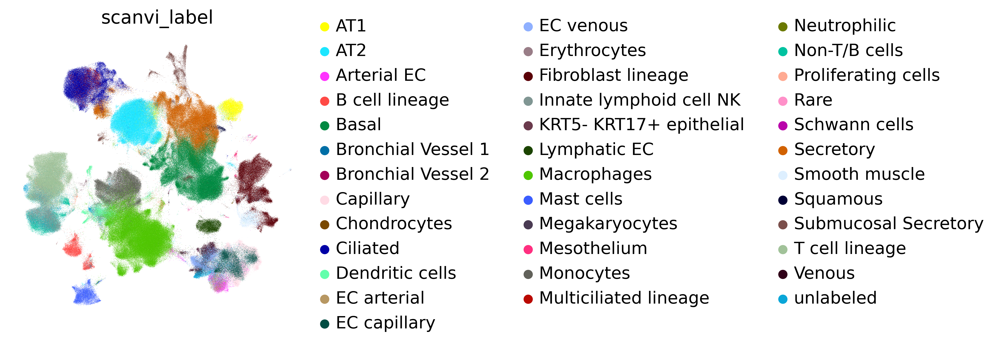

In [39]:
sc.pl.umap(combined_data, color=cell_type_key, frameon=False)

In [40]:
#scANVI_model = sca.models.SCANVI.from_scvi_model(scvi_model, unlabeled_category, adata=combined_data)

In [41]:
#scANVI_model.train(max_epochs=scanvi_epochs, n_samples_per_label=100, early_stopping=True)

In [42]:
#scANVI_model.save("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/scANVI")

In [43]:
scANVI_model = sca.models.SCANVI.load("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/scANVI", combined_data)

INFO     Using data from adata.layers["counts"]                                              
INFO     Computing library size prior per batch                                              
INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     
INFO     Successfully registered anndata object containing 713512 cells, 2000 vars, 16       
         batches, 37 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  


In [44]:
print("Labelled Indices: ", len(scANVI_model._labeled_indices))
print("Unlabelled Indices: ", len(scANVI_model._unlabeled_indices))

Labelled Indices:  689338
Unlabelled Indices:  24174


In [45]:
combined_data.obs["C_scANVI"] = scANVI_model.predict(combined_data)
combined_data.obsm["X_scANVI"] = scANVI_model.get_latent_representation(combined_data)

In [46]:
sc.pp.neighbors(combined_data, use_rep="X_scANVI")
sc.tl.umap(combined_data)

... storing 'C_scANVI' as categorical


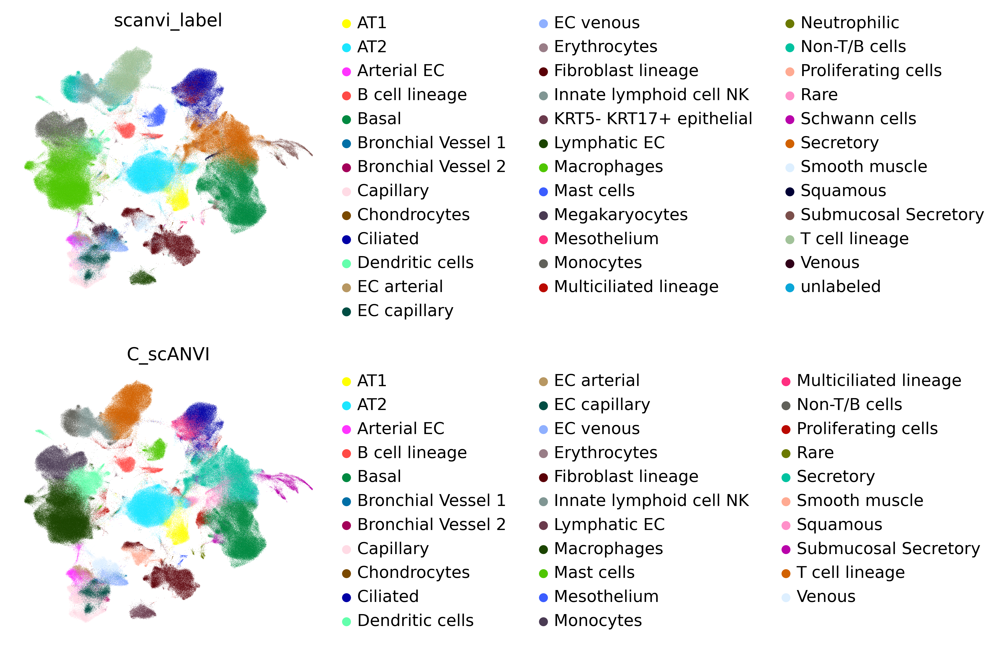

In [47]:
sc.pl.umap(combined_data, color=["scanvi_label", "C_scANVI"], ncols=1, frameon=False)

In [48]:
df = combined_data.obs.groupby(["scanvi_label", "C_scANVI"]).size().unstack(fill_value=0)

Text(0, 0.5, 'Observed')

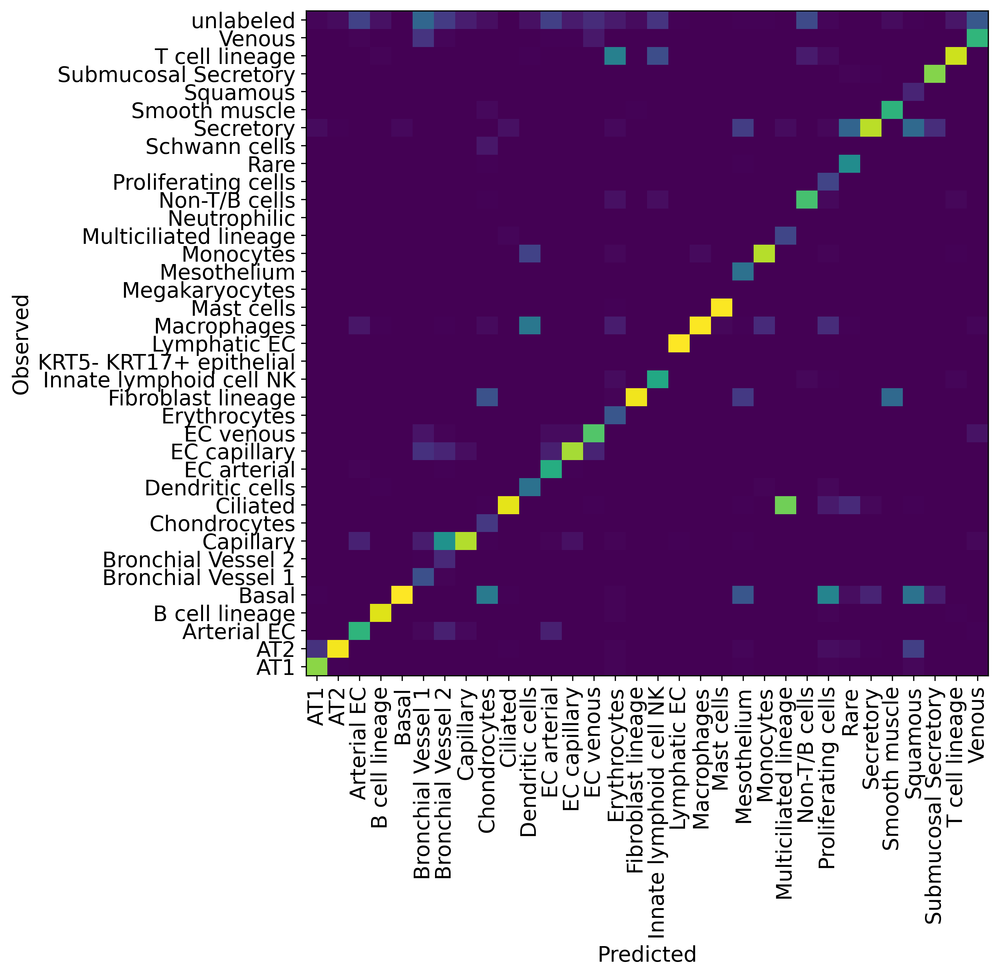

In [49]:
df = df / df.sum(axis=0)

plt.figure(figsize=(8, 8))
_ = plt.pcolor(df)
_ = plt.xticks(np.arange(0.5, len(df.columns), 1), df.columns, rotation=90)
_ = plt.yticks(np.arange(0.5, len(df.index), 1), df.index)
plt.xlabel("Predicted")
plt.ylabel("Observed")

In [50]:
#combined_data.write("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/learned_atlas/Meyer2021_atlas_denovo.h5ad")

### 1.3 scVI and scANVI model with old reference HVGs

In [51]:
sca.dataset.setup_anndata(combined_data_ref_hvg, layer="counts", batch_key=condition_key, labels_key=cell_type_key)

INFO     Using batches from adata.obs["dataset"]                                             
INFO     Using labels from adata.obs["scanvi_label"]                                         
INFO     Using data from adata.layers["counts"]                                              
INFO     Computing library size prior per batch                                              
INFO     Successfully registered anndata object containing 713512 cells, 2000 vars, 16       
         batches, 37 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  
INFO     Please do not further modify adata until model is trained.                          


Default parameters, except n_latent=30 (higher than default) since we're processing large data with diverse cell types (was also used in benchmarking), and gene_likelihood='nb' instead of zinb since all data are UMI based (hence negative binomially distributed).

In [52]:
scvi_model_ref_hvg = sca.models.SCVI(
    combined_data_ref_hvg,
    n_layers=2,
    n_latent=30, 
    encode_covariates=True,
    deeply_inject_covariates=False,
    use_layer_norm="both",
    use_batch_norm="none",
    gene_likelihood="nb"
)

In [ ]:
scvi_model_ref_hvg.train(max_epochs=scvi_epochs, early_stopping=True)

GPU available: True, used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Set SLURM handle signals.


Epoch 222/500:  44%|████▍     | 221/500 [4:38:33<6:05:31, 78.61s/it, loss=569, v_num=1]

In [ ]:
scvi_model_ref_hvg.save("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/scVI_ref_hvg")

In [ ]:
#scvi_model_ref_hvg = sca.models.SCVI.load("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/scVI_ref_hvg", combined_data_ref_hvg)

In [ ]:
combined_data_ref_hvg.obsm["X_scVI"] = scvi_model_ref_hvg.get_latent_representation()

In [ ]:
sc.pp.neighbors(combined_data_ref_hvg, use_rep="X_scVI")
sc.tl.leiden(combined_data_ref_hvg)
sc.tl.umap(combined_data_ref_hvg)

In [ ]:
sc.pl.umap(
    combined_data_ref_hvg,
    color=["dataset", "leiden"],
    frameon=False,
    ncols=1,
)

In [ ]:
sc.pl.umap(combined_data_ref_hvg, color=cell_type_key, frameon=False)

In [ ]:
scANVI_model_ref_hvg = sca.models.SCANVI.from_scvi_model(scvi_model_ref_hvg, unlabeled_category, adata=combined_data_ref_hvg)

In [ ]:
scANVI_model_ref_hvg.train(max_epochs=scanvi_epochs, n_samples_per_label=100, early_stopping=True)

In [ ]:
scANVI_model_ref_hvg.save("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/scANVI_ref_hvg")

In [ ]:
#scANVI_model_ref_hvg = sca.models.SCANVI.load("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/scANVI_ref_hvg", combined_data_ref_hvg)

In [ ]:
print("Labelled Indices: ", len(scANVI_model_ref_hvg._labeled_indices))
print("Unlabelled Indices: ", len(scANVI_model_ref_hvg._unlabeled_indices))

In [ ]:
combined_data_ref_hvg.obs["C_scANVI"] = scANVI_model_ref_hvg.predict(combined_data_ref_hvg)
combined_data_ref_hvg.obsm["X_scANVI"] = scANVI_model_ref_hvg.get_latent_representation(combined_data_ref_hvg)

In [ ]:
sc.pp.neighbors(combined_data_ref_hvg, use_rep="X_scANVI")
sc.tl.umap(combined_data_ref_hvg)

In [ ]:
sc.pl.umap(combined_data_ref_hvg, color=["scanvi_label", "C_scANVI"], ncols=1, frameon=False)

In [ ]:
df = combined_data_ref_hvg.obs.groupby(["scanvi_label", "C_scANVI"]).size().unstack(fill_value=0)

In [ ]:
df = df / df.sum(axis=0)

plt.figure(figsize=(8, 8))
_ = plt.pcolor(df)
_ = plt.xticks(np.arange(0.5, len(df.columns), 1), df.columns, rotation=90)
_ = plt.yticks(np.arange(0.5, len(df.index), 1), df.index)
plt.xlabel("Predicted")
plt.ylabel("Observed")

In [73]:
combined_data_ref_hvg.write("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/learned_atlas/Meyer2021_atlas_denovo_ref_hvg.h5ad")

## 2. scArches | Perform surgery 

atlas_data contains the raw counts in all levels (.X,.raw,.layers\['counts'\])

Prepare query data for scArches: set all labels to unlabeled

In [74]:
query_data.obs["scanvi_label_original"]=query_data.obs["scanvi_label"]

In [75]:
query_data.obs["scanvi_label"]=scANVI_model.unlabeled_category_

In [76]:
query_data_scArches = query_data[:,np.unique(atlas_data.var.gene_ids)].copy()

In [78]:
scVI_model_original = sca.models.SCVI.load("/storage/groups/ml01/workspace/jan.domke/Data/Models/scVI", atlas_data)

INFO     Using data from adata.X                                                             
INFO     Computing library size prior per batch                                              
INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     
INFO     Successfully registered anndata object containing 584884 cells, 2000 vars, 14       
         batches, 29 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  


In [79]:
scANVI_model_original = sca.models.SCANVI.load("/storage/groups/ml01/workspace/jan.domke/Data/Models/scANVI", atlas_data)

INFO     Using data from adata.X                                                             
INFO     Computing library size prior per batch                                              
INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     
INFO     Successfully registered anndata object containing 584884 cells, 2000 vars, 14       
         batches, 29 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  


In [80]:
scArches_model = sca.models.SCANVI.load_query_data(
    query_data_scArches,
    scANVI_model_original,
    freeze_dropout = True,
)
scArches_model._unlabeled_indices = np.arange(query_data_scArches.n_obs)
scArches_model._labeled_indices = []
print("Labelled Indices: ", len(scArches_model._labeled_indices))
print("Unlabelled Indices: ", len(scArches_model._unlabeled_indices))

INFO     Using data from adata.X                                                             
INFO     Computing library size prior per batch                                              
INFO     Registered keys:['X', 'batch_indices', 'local_l_mean', 'local_l_var', 'labels']     
INFO     Successfully registered anndata object containing 128628 cells, 2000 vars, 16       
         batches, 29 labels, and 0 proteins. Also registered 0 extra categorical covariates  
         and 0 extra continuous covariates.                                                  
Labelled Indices:  0
Unlabelled Indices:  128628


In [81]:
scArches_model.train(max_epochs=200, plan_kwargs=dict(weight_decay=0.0))
query_data_scArches.obsm["X_scVI"] = scArches_model.get_latent_representation()

INFO     Training for 200 epochs.                                                            


GPU available: True, used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
Set SLURM handle signals.


Epoch 200/200: 100%|██████████| 200/200 [1:00:57<00:00, 18.29s/it, loss=637, v_num=1]


In [83]:
query_data_scArches.write("/storage/groups/ml01/workspace/jan.domke/Data/Models/Meyer2021/learned_atlas/Meyer2021_atlas_scArches.h5ad")

... storing 'scanvi_label' as categorical
